<a href="https://colab.research.google.com/github/James1-loki/alphagroup/blob/main/01_probability_neural_networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 1.1: Probability & Neural Networks for Digital Twins

## Learning Objectives
- Understand how AI makes predictions using probability
- Learn the basics of neural networks
- Apply these concepts to building a digital twin

## Digital Twin Context
A **digital twin** is a virtual representation of a physical entity (person, object, system). In this series, we'll build a digital twin that can:
- Predict behaviors and preferences
- Understand and respond to language
- Learn from interactions

## Key Insight
> "AI isn't thinking; it's predicting the next number."

This applies to everything from weather prediction to language generation!

---
## Part 1: Probability Foundations

Let's start with the basics: How does AI make predictions?

In [20]:
# Import required libraries
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
import pandas as pd

# Set random seed for reproducibility
np.random.seed(42)

print("✅ Libraries loaded successfully!")

✅ Libraries loaded successfully!


### 1.1 Simple Prediction: Next Number

Let's simulate a digital twin predicting your next action based on historical data.

Activity Probabilities:
  Sleep: 20.00%
  Work: 40.00%
  Exercise: 13.33%
  Social: 13.33%
  Leisure: 13.33%


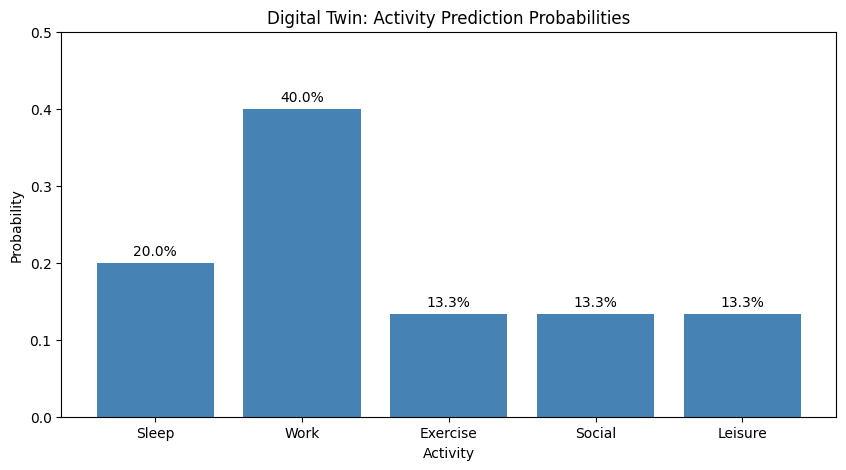

In [21]:
from collections import Counter
import matplotlib.pyplot as plt

# Example: Predicting daily activities (represented as numbers)
# 0=Sleep, 1=Work, 2=Exercise, 3=Social, 4=Leisure

historical_activities = [0, 1, 2, 1, 3, 1, 4, 0, 1, 2, 1, 3, 1, 4, 0]

def calculate_probabilities(sequence):
    """
    Calculate probability distribution from a sequence.

    Args:
        sequence: List of integers representing activities

    Returns:
        dict: Probability of each activity
    """
    counts = Counter(sequence)
    total = len(sequence)
    probabilities = {activity: count/total for activity, count in counts.items()}
    return probabilities

# Calculate probabilities
probs = calculate_probabilities(historical_activities)

# Display results
activity_names = {0: 'Sleep', 1: 'Work', 2: 'Exercise', 3: 'Social', 4: 'Leisure'}
print("Activity Probabilities:")
for activity, prob in sorted(probs.items()):
    print(f"  {activity_names[activity]}: {prob:.2%}")

# Visualize
plt.figure(figsize=(10, 5))
activities = [activity_names[k] for k in sorted(probs.keys())]
probabilities = [probs[k] for k in sorted(probs.keys())]
plt.bar(activities, probabilities, color='steelblue')
plt.title('Digital Twin: Activity Prediction Probabilities')
plt.ylabel('Probability')
plt.xlabel('Activity')
plt.ylim(0, 0.5)
for i, v in enumerate(probabilities):
    plt.text(i, v + 0.01, f'{v:.1%}', ha='center')
plt.show()

### 🎯 Exercise 1.1 (Easy): Understanding Probabilities

**Task**: Modify the historical activities to represent your own daily routine for 2 weeks (14 days).

**Questions**:
1. Which activity has the highest probability?
2. What does this tell you about the pattern in your data?
3. How would adding more data points affect the predictions?

In [22]:
# YOUR CODE HERE
# Create your own sequence of activities (14 values)
my_activities = [0, 1, 1, 1, 1, 1, 2, 0, 1, 1, 1, 1, 1, 4]  # Replace with your pattern

# Calculate and visualize
my_probs = calculate_probabilities(my_activities)

# YOUR ANALYSIS HERE (write answers as comments)
# 1. Highest probability activity.
# Activity 1 (Work) has the highest probability. It occurred 10 out of 14 times (~71.4%).

# 2. Pattern insight:
# My data reveals that Work takes up most of my routine. There isn't much variation in the activities since Work appears repeatedly, while Sleep, Exercise and Leisure occur less often.
# This means my digital twin would most likely predict that I am working.

# 3. Impact of more data:
# If I collect data over a longer period, the results will give a better picture of my actual routine. Fourteen activities may not
# be enough to show my usual habits, especially if some days are different from others. More data would help make the predictions
# more accurate.

### 1.2 Conditional Probability: Context Matters

What if predictions depend on previous activities? This is where context comes in!

In [23]:
def calculate_conditional_probabilities(sequence):
    """
    Calculate P(next | current) - probability of next activity given current.

    Args:
        sequence: List of activities

    Returns:
        dict: Nested dictionary of conditional probabilities
    """
    transitions = {}

    for i in range(len(sequence) - 1):
        current = sequence[i]
        next_activity = sequence[i + 1]

        if current not in transitions:
            transitions[current] = []
        transitions[current].append(next_activity)

    # Convert to probabilities
    conditional_probs = {}
    for current, next_list in transitions.items():
        counts = Counter(next_list)
        total = len(next_list)
        conditional_probs[current] = {activity: count/total for activity, count in counts.items()}

    return conditional_probs

# Calculate conditional probabilities
cond_probs = calculate_conditional_probabilities(historical_activities)

# Display
print("Conditional Probabilities: P(Next | Current)\n")
for current, next_probs in cond_probs.items():
    print(f"After {activity_names[current]}:")
    for next_activity, prob in sorted(next_probs.items()):
        print(f"  → {activity_names[next_activity]}: {prob:.2%}")
    print()

Conditional Probabilities: P(Next | Current)

After Sleep:
  → Work: 100.00%

After Work:
  → Exercise: 33.33%
  → Social: 33.33%
  → Leisure: 33.33%

After Exercise:
  → Work: 100.00%

After Social:
  → Work: 100.00%

After Leisure:
  → Sleep: 100.00%



### 🎯 Exercise 1.2 (Intermediate): Markov Chain Prediction

**Task**: Build a simple predictor that uses conditional probabilities to predict the next activity.

**Challenge**: What happens after "Work"? Which activity is most likely?

In [24]:
def predict_next_activity(current_activity, conditional_probs):
    """
    Predict the most likely next activity.

    Args:
        current_activity: Current activity code
        conditional_probs: Dictionary of conditional probabilities

    Returns:
        int: Most likely next activity
    """
    # YOUR CODE HERE
    # Hint: Find the activity with maximum probability given current_activity
    if current_activity not in conditional_probs:
        return None

    next_probs = conditional_probs[current_activity]
    # Complete this function

    return max(next_probs, key=next_probs.get)

# Test your function
current = 1  # Work
predicted = predict_next_activity(current, cond_probs)
print(f"After {activity_names[current]}, most likely next: {activity_names.get(predicted, 'Unknown')}")

# BONUS: Predict a sequence of 5 activities starting from "Work"

After Work, most likely next: Exercise


---
## Part 2: Neural Networks Basics

Now let's see how neural networks learn to make predictions!

### 2.1 The Perceptron: Building Block of Neural Networks

A perceptron is the simplest neural network - it takes inputs, applies weights, and produces an output.

In [25]:
import numpy as np

def sigmoid(x):
    """Sigmoid activation function."""
    return 1 / (1 + np.exp(-x))

def perceptron(inputs, weights, bias):
    """
    Simple perceptron implementation.

    Args:
        inputs: Array of input values
        weights: Array of weights
        bias: Bias term

    Returns:
        float: Output after activation
    """
    # Calculate weighted sum
    weighted_sum = np.dot(inputs, weights) + bias
    # Apply activation function
    output = sigmoid(weighted_sum)
    return output

# Example: Predicting if someone will exercise based on features
# Features: [hours_of_sleep, free_time_hours, energy_level (0-1)]
person_features = np.array([7, 2, 0.8])  # 7 hours sleep, 2 hours free time, high energy

# Initialize random weights
weights = np.array([0.3, 0.5, 0.7])
bias = -0.5

prediction = perceptron(person_features, weights, bias)
print(f"Probability of exercising: {prediction:.2%}")
print(f"Prediction: {'Will exercise' if prediction > 0.5 else 'Will not exercise'}")

Probability of exercising: 95.93%
Prediction: Will exercise


### 🎯 Exercise 2.1 (Easy): Feature Engineering

**Task**: Modify the features and observe how the prediction changes.

**Questions**:
1. What happens when sleep hours decrease to 4?
2. What if free time increases to 4 hours?
3. Which feature seems to have the most impact based on the weights?

In [26]:
# YOUR CODE HERE
# Test different feature combinations

test_cases = [
    np.array([4, 2, 0.8]),  # Low sleep
    np.array([7, 4, 0.8]),  # More free time
    np.array([7, 2, 0.3]),  # Low energy
]

# Test each case and analyze results

for i, features in enumerate(test_cases):

    prediction = perceptron(features, weights, bias)

    print(f"Test Case {i + 1}")
    print(f"Input Features: {features}")
    print(f"Probability of exercising: {prediction:.2%}")

    if prediction > 0.5:
        print("Prediction: Will exercise")
    else:
        print("Prediction: Will not exercise")

    print("-" * 40)



Test Case 1
Input Features: [4.  2.  0.8]
Probability of exercising: 90.55%
Prediction: Will exercise
----------------------------------------
Test Case 2
Input Features: [7.  4.  0.8]
Probability of exercising: 98.46%
Prediction: Will exercise
----------------------------------------
Test Case 3
Input Features: [7.  2.  0.3]
Probability of exercising: 94.32%
Prediction: Will exercise
----------------------------------------


### 2.2 Training a Simple Neural Network





Let's see how a network learns by adjusting weights!

In [27]:
class SimpleNeuralNetwork:
    """A simple neural network with one hidden layer."""

    def __init__(self, input_size, hidden_size, output_size):
        # Initialize weights randomly
        self.W1 = np.random.randn(input_size, hidden_size) * 0.5
        self.b1 = np.zeros((1, hidden_size))
        self.W2 = np.random.randn(hidden_size, output_size) * 0.5
        self.b2 = np.zeros((1, output_size))

        # Store training history
        self.loss_history = []

    def forward(self, X):
        """Forward pass through the network."""
        self.z1 = np.dot(X, self.W1) + self.b1
        self.a1 = sigmoid(self.z1)
        self.z2 = np.dot(self.a1, self.W2) + self.b2
        self.a2 = sigmoid(self.z2)
        return self.a2

    def backward(self, X, y, output, learning_rate=0.1):
        """Backward pass - update weights."""
        m = X.shape[0]

        # Calculate gradients
        dz2 = output - y
        dW2 = np.dot(self.a1.T, dz2) / m
        db2 = np.sum(dz2, axis=0, keepdims=True) / m

        da1 = np.dot(dz2, self.W2.T)
        dz1 = da1 * self.a1 * (1 - self.a1)
        dW1 = np.dot(X.T, dz1) / m
        db1 = np.sum(dz1, axis=0, keepdims=True) / m

        # Update weights
        self.W2 -= learning_rate * dW2
        self.b2 -= learning_rate * db2
        self.W1 -= learning_rate * dW1
        self.b1 -= learning_rate * db1

    def train(self, X, y, epochs=1000, learning_rate=0.1):
        """Train the network."""
        for epoch in range(epochs):
            # Forward pass
            output = self.forward(X)

            # Calculate loss
            loss = np.mean((output - y) ** 2)
            self.loss_history.append(loss)

            # Backward pass
            self.backward(X, y, output, learning_rate)

            if epoch % 100 == 0:
                print(f"Epoch {epoch}, Loss: {loss:.4f}")

    def predict(self, X):
        """Make predictions."""
        return self.forward(X)

# Create training data for digital twin
# Features: [day_of_week (0-6), time_of_day (0-23), weather (0-1), mood (0-1)]
# Target: [probability of social activity]

np.random.seed(42)
X_train = np.random.rand(100, 4)
# Simulate pattern: social activity more likely on weekends (day > 5) and good weather
y_train = ((X_train[:, 0] > 0.7) & (X_train[:, 2] > 0.5)).astype(float).reshape(-1, 1)
y_train += np.random.rand(100, 1) * 0.2  # Add noise
y_train = np.clip(y_train, 0, 1)

# Create and train network
nn = SimpleNeuralNetwork(input_size=4, hidden_size=8, output_size=1)
print("Training neural network...\n")
nn.train(X_train, y_train, epochs=500, learning_rate=0.5)

Training neural network...

Epoch 0, Loss: 0.5069
Epoch 100, Loss: 0.1061
Epoch 200, Loss: 0.0863
Epoch 300, Loss: 0.0678
Epoch 400, Loss: 0.0550


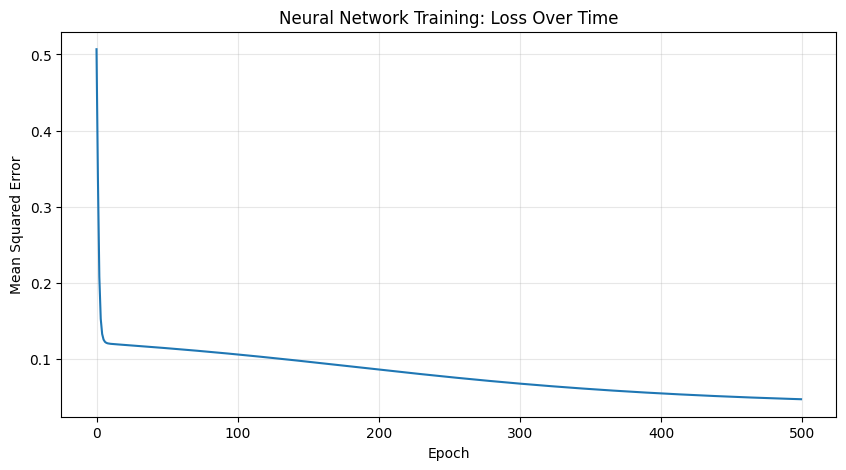


Final loss: 0.0474


In [28]:
# Visualize training progress
plt.figure(figsize=(10, 5))
plt.plot(nn.loss_history)
plt.title('Neural Network Training: Loss Over Time')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.grid(True, alpha=0.3)
plt.show()

print(f"\nFinal loss: {nn.loss_history[-1]:.4f}")

### 🎯 Exercise 2.2 (Intermediate): Digital Twin Prediction

**Task**: Test the trained network on new scenarios and interpret results.

**Scenarios to test**:
1. Weekend evening (day=6, time=18, weather=0.8, mood=0.9)
2. Weekday morning (day=2, time=8, weather=0.3, mood=0.5)
3. Weekend with bad weather (day=5, time=14, weather=0.2, mood=0.6)

In [29]:
# YOUR CODE HERE
# Normalize inputs (scale to 0-1 range)
# Helper function to normalize inputs to scale [0, 1]
def normalize_input(day, time, weather, mood):
    return np.array([[day / 7.0, time / 24.0, weather, mood]])

# Define test scenarios: (name, day, time, weather, mood)
scenarios = [
    ("Weekend evening, good weather", 6, 18, 0.8, 0.9),
    ("Weekday morning, poor weather", 2, 8, 0.3, 0.5),
    ("Weekend afternoon, bad weather", 5, 14, 0.2, 0.6)
]

# Make predictions and display results
for name, day, time, weather, mood in scenarios:
    X_test = normalize_input(day, time, weather, mood)
    prediction = nn.predict(X_test)
    print(f"{name}:")
    print(f"  Social activity probability: {prediction[0][0]:.2%}\n")

Weekend evening, good weather:
  Social activity probability: 72.61%

Weekday morning, poor weather:
  Social activity probability: 6.27%

Weekend afternoon, bad weather:
  Social activity probability: 22.70%



### 🎯 Exercise 2.3 (Advanced): Improve the Digital Twin

**Task**: Enhance the neural network to make better predictions.

**Challenges**:
1. Add more training data with realistic patterns
2. Experiment with different network architectures (hidden layer size)
3. Try different learning rates
4. Add a second hidden layer
5. Create a visualization showing prediction accuracy

Epoch 0, Loss: 0.1193
Epoch 100, Loss: 0.0378
Epoch 200, Loss: 0.0364
Epoch 300, Loss: 0.0351
Epoch 400, Loss: 0.0335
Epoch 500, Loss: 0.0315
Epoch 600, Loss: 0.0292
Epoch 700, Loss: 0.0266
Epoch 0, Loss: 0.0377
Epoch 100, Loss: 0.0320
Epoch 200, Loss: 0.0285
Epoch 300, Loss: 0.0250
Epoch 400, Loss: 0.0217
Epoch 500, Loss: 0.0190
Epoch 600, Loss: 0.0169
Epoch 700, Loss: 0.0154
Epoch 0, Loss: 0.0342
Epoch 100, Loss: 0.0240
Epoch 200, Loss: 0.0186
Epoch 300, Loss: 0.0158
Epoch 400, Loss: 0.0144
Epoch 500, Loss: 0.0137
Epoch 600, Loss: 0.0134
Epoch 700, Loss: 0.0132


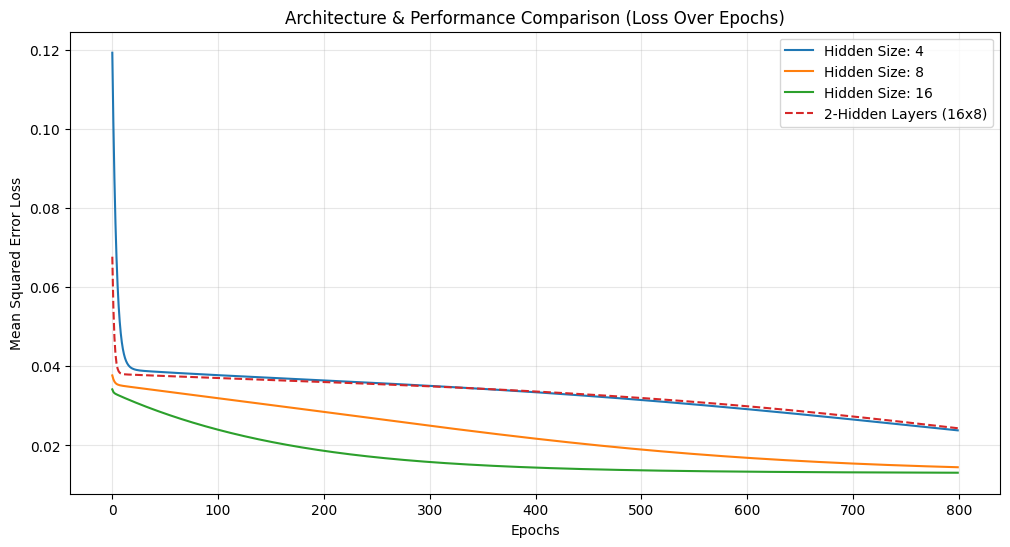

--- Final Performance Summary (Lower Loss = Better) ---
Hidden Size: 4: Final MSE Loss = 0.02381
Hidden Size: 8: Final MSE Loss = 0.01449
Hidden Size: 16: Final MSE Loss = 0.01310
2-Hidden Layers (16x8): Final MSE Loss = 0.02435


In [30]:
# YOUR CODE HERE
# Challenge: Create a better training dataset

import matplotlib.pyplot as plt
import numpy as np


# 1. Challenge: Create a better training dataset
def generate_realistic_data(n_samples=500):
  """Generate more realistic training data for digital twin."""
  np.random.seed(42)

  # Features: [day (0-6), time (0-23), weather (0-1), mood (0-1)]
  day = np.random.uniform(0, 6, (n_samples, 1))
  time = np.random.uniform(0, 23, (n_samples, 1))
  weather = np.random.uniform(0, 1, (n_samples, 1))
  mood = np.random.uniform(0, 1, (n_samples, 1))

  # Combine raw features
  X_raw = np.hstack([day, time, weather, mood])

  # Normalize features to [0, 1] range for training
  X = np.hstack([day / 6.0, time / 23.0, weather, mood])

  # Pattern rules:
  # - Weekend (day > 4): higher probability
  # - Evening (time > 16): higher probability
  # - Good weather & good mood increase probability
  weekend_factor = np.where(day >= 4, 0.35, 0.05)
  evening_factor = np.where((time >= 16) & (time <= 22), 0.25, 0.05)
  weather_factor = weather * 0.20
  mood_factor = mood * 0.20

  # Calculate target probability with slight random noise
  y_prob = (
      weekend_factor + evening_factor + weather_factor + mood_factor
  ) + np.random.normal(0, 0.05, (n_samples, 1))
  y = np.clip(y_prob, 0, 1)

  return X, y


# Generate 500 samples of realistic data
X_train, y_train = generate_realistic_data(n_samples=500)


# 2 & 4. Enhanced Neural Network with 2 Hidden Layers Option
class DeepNeuralNetwork:

  def __init__(self, input_size, hidden1_size, hidden2_size, output_size):
    self.W1 = np.random.randn(input_size, hidden1_size) * 0.5
    self.b1 = np.zeros((1, hidden1_size))
    self.W2 = np.random.randn(hidden1_size, hidden2_size) * 0.5
    self.b2 = np.zeros((1, hidden2_size))
    self.W3 = np.random.randn(hidden2_size, output_size) * 0.5
    self.b3 = np.zeros((1, output_size))
    self.loss_history = []

  def sigmoid(self, z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

  def forward(self, X):
    self.z1 = np.dot(X, self.W1) + self.b1
    self.a1 = self.sigmoid(self.z1)
    self.z2 = np.dot(self.a1, self.W2) + self.b2
    self.a2 = self.sigmoid(self.z2)
    self.z3 = np.dot(self.a2, self.W3) + self.b3
    self.a3 = self.sigmoid(self.z3)
    return self.a3

  def backward(self, X, y, output, learning_rate=0.1):
    m = X.shape[0]

    dz3 = output - y
    dW3 = np.dot(self.a2.T, dz3) / m
    db3 = np.sum(dz3, axis=0, keepdims=True) / m

    da2 = np.dot(dz3, self.W3.T)
    dz2 = da2 * self.a2 * (1 - self.a2)
    dW2 = np.dot(self.a1.T, dz2) / m
    db2 = np.sum(dz2, axis=0, keepdims=True) / m

    da1 = np.dot(dz2, self.W2.T)
    dz1 = da1 * self.a1 * (1 - self.a1)
    dW1 = np.dot(X.T, dz1) / m
    db1 = np.sum(dz1, axis=0, keepdims=True) / m

    self.W3 -= learning_rate * dW3
    self.b3 -= learning_rate * db3
    self.W2 -= learning_rate * dW2
    self.b2 -= learning_rate * db2
    self.W1 -= learning_rate * dW1
    self.b1 -= learning_rate * db1

  def train(self, X, y, epochs=1000, learning_rate=0.1):
    for epoch in range(epochs):
      output = self.forward(X)
      loss = np.mean((output - y) ** 2)
      self.loss_history.append(loss)
      self.backward(X, y, output, learning_rate)


# 2 & 3. Test different architectures and learning rates
architectures = [(4, 4, 1), (4, 8, 1), (4, 16, 1)]  #
learning_rates = [0.05, 0.1, 0.5]

results = {}

plt.figure(figsize=(12, 6))

# Compare architectures on Single-Hidden-Layer Network (SimpleNeuralNetwork)
for input_size, hidden_size, output_size in architectures:  #
  nn = SimpleNeuralNetwork(input_size, hidden_size, output_size)  #[cite: 1, 3]
  nn.train(X_train, y_train, epochs=800, learning_rate=0.3)
  label = f'Hidden Size: {hidden_size}'
  results[label] = nn.loss_history[-1]
  plt.plot(nn.loss_history, label=label)

# 4. Train a 2-Hidden-Layer Architecture
dnn = DeepNeuralNetwork(
    input_size=4, hidden1_size=16, hidden2_size=8, output_size=1
)
dnn.train(X_train, y_train, epochs=800, learning_rate=0.3)
results['2-Hidden Layers (16x8)'] = dnn.loss_history[-1]
plt.plot(dnn.loss_history, label='2-Hidden Layers (16x8)', linestyle='--')

# 5. Create a visualization showing loss and model comparison
plt.title('Architecture & Performance Comparison (Loss Over Epochs)')
plt.xlabel('Epochs')
plt.ylabel('Mean Squared Error Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Print accuracy / final loss evaluation summary
print('--- Final Performance Summary (Lower Loss = Better) ---')
for arch, loss in results.items():
  print(f'{arch}: Final MSE Loss = {loss:.5f}')

---
## Part 3: Connecting to LLMs

How does this relate to Large Language Models?

### 3.1 From Activities to Words

LLMs work exactly like our activity predictor, but with words!

Given text: I love coding in Python because it is

Predicted next word probabilities:
  elegant: 25.62%
  versatile: 18.85%
  fun: 15.51%
  clear: 11.22%
  simple: 10.48%
  easy: 10.31%
  powerful: 8.01%


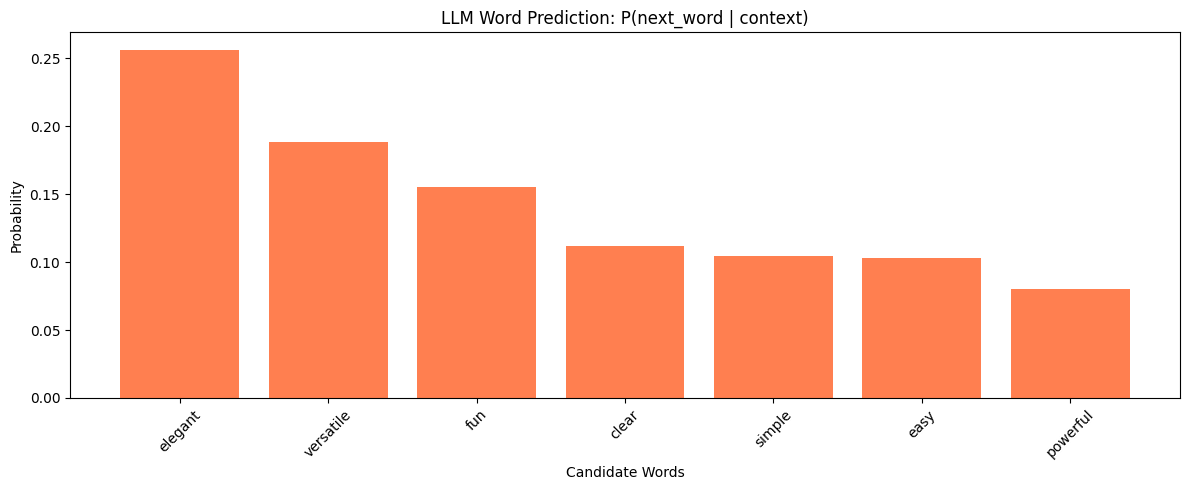

In [31]:
# Simple word prediction example
text_sequence = "I love coding in Python because it is"
words = text_sequence.split()

# Simulate word prediction
word_vocab = ['fun', 'easy', 'powerful', 'versatile', 'simple', 'clear', 'elegant']
word_probs = np.random.rand(len(word_vocab))
word_probs = word_probs / word_probs.sum()  # Normalize to probabilities

# Create probability distribution
word_dist = dict(zip(word_vocab, word_probs))
word_dist = dict(sorted(word_dist.items(), key=lambda x: x[1], reverse=True))

print("Given text:", text_sequence)
print("\nPredicted next word probabilities:")
for word, prob in word_dist.items():
    print(f"  {word}: {prob:.2%}")

# Visualize
plt.figure(figsize=(12, 5))
plt.bar(word_dist.keys(), word_dist.values(), color='coral')
plt.title('LLM Word Prediction: P(next_word | context)')
plt.ylabel('Probability')
plt.xlabel('Candidate Words')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 🎯 Exercise 3.1 (Conceptual): Understanding LLMs

**Questions**:
1. How is predicting the next word similar to predicting the next activity?
2. What role does probability play in both cases?
3. Why might an LLM sometimes generate unexpected words?
4. How does context (previous words) help make better predictions?

Write your answers in the cell below:

**Your Answers:**

1. Similarity between word and activity prediction:
   - Both tasks rely on identifying patterns in sequences and contexts to assign probabilities to potential outcomes. Just as the activity predictor estimates the likelihood of doing an activity based on factors like time, day, weather, and mood, an LLM predicts the most likely next word based on preceding words in a prompt.

2. Role of probability:
   - Probability quantifies uncertainty and allows models to rank all possible outputs instead of making rigid, single-outcome guesses. In both systems, output values are normalized using functions like softmax or scaling so that all probabilities sum to $1.0$ ($100\%$), enabling weighted selection.

3. Unexpected generations:
   - Unexpected generations happen because LLMs sample probabilistically from a distribution rather than always selecting the absolute highest-probability word. Additionally, noise, ambiguous input prompts, or unexpected combinations in the training data can shift the probability distribution towards lower-ranked words.

4. Importance of context:
   - Context provides the necessary conditional information to narrow down possibilities. For example, the sentence "I love coding in Python because it is" heavily restricts candidate words to positive descriptors like "powerful", "simple", or "versatile". Without context, the model would only output generic unigram frequencies.

---
## Summary & Key Takeaways

### What We Learned:
1. **Probability**: AI predicts by calculating probabilities based on historical patterns
2. **Conditional Probability**: Context matters - knowing what came before improves predictions
3. **Neural Networks**: Learn patterns by adjusting weights through training
4. **Digital Twin**: Can model behaviors using probabilistic predictions
5. **LLM Connection**: Language models are sophisticated versions of these basic concepts

### Next Steps:
In the next notebook, we'll explore:
- How LLMs represent words (embeddings)
- Transformer architecture
- Attention mechanisms
- Building a simple language model for your digital twin

---
## 🏆 Challenge Project (Advanced)

**Build Your Own Digital Twin Predictor**

Create a system that:
1. Collects data about your daily patterns (sleep, activities, mood, etc.)
2. Trains a neural network to predict your next likely activity
3. Evaluates prediction accuracy
4. Visualizes patterns it learned

**Bonus**: Add temporal features (day of week, time of day) and see how they improve predictions!

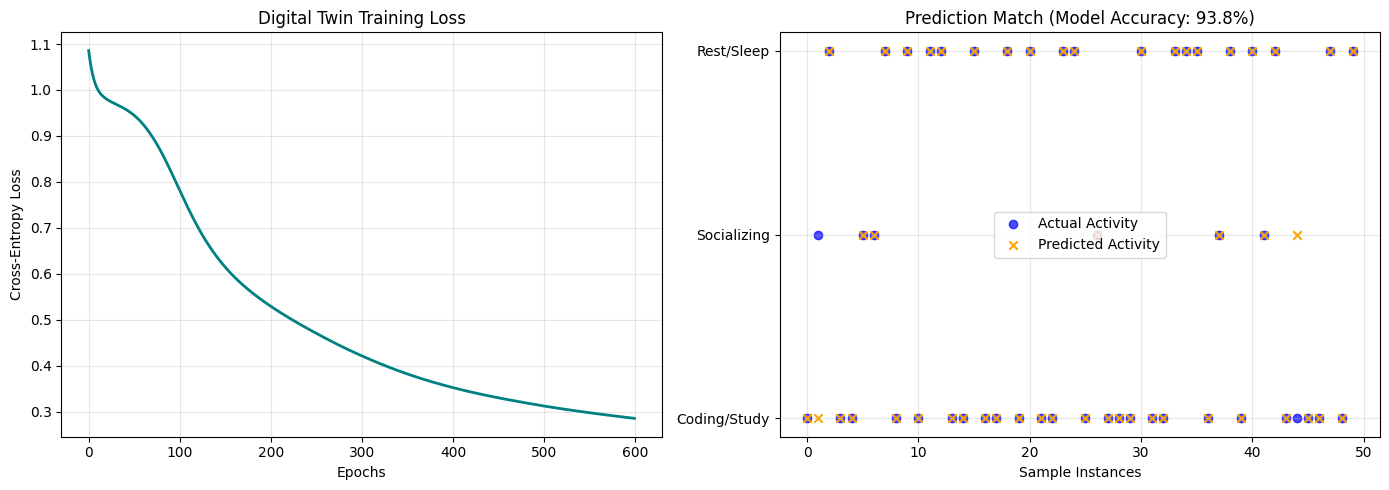

Overall Digital Twin Accuracy: 93.80%


In [32]:
# YOUR CHALLENGE PROJECT CODE HERE
# This is your space to be creative!
import matplotlib.pyplot as plt
import numpy as np

# Set seed for reproducibility
np.random.seed(42)


# 1. Collect / Generate synthetic daily pattern data
def generate_digital_twin_dataset(n_samples=1000):
  # Features: [sleep_hours (4-10), mood (0-1), day_of_week (0-6), time_of_day (0-23)]
  sleep = np.random.uniform(4, 10, (n_samples, 1))
  mood = np.random.uniform(0, 1, (n_samples, 1))
  day = np.random.uniform(0, 6, (n_samples, 1))
  time = np.random.uniform(0, 23, (n_samples, 1))

  # Target activities: 0 = Coding/Study, 1 = Socializing, 2 = Rest/Sleep
  # Define rules for ground truth logic
  logits_coding = (time >= 9) & (time <= 17) & (day < 5)  # Weekday work hours
  logits_social = (time > 17) & (mood > 0.5)  # Evenings with good mood
  logits_rest = (time < 8) | (time > 22)  # Early morning / late night

  # Combine into targets
  y_raw = np.zeros((n_samples, 1))
  for i in range(n_samples):
    if logits_social[i]:
      y_raw[i] = 1
    elif logits_rest[i]:
      y_raw[i] = 2
    else:
      y_raw[i] = 0

  # Normalize features to [0, 1] range
  X_norm = np.hstack([sleep / 10.0, mood, day / 6.0, time / 23.0])

  return X_norm, y_raw.astype(int)


# 2. Train Neural Network (Multi-class Digital Twin)
class MultiClassDigitalTwin:

  def __init__(self, input_dim, hidden_dim, output_dim):
    self.W1 = np.random.randn(input_dim, hidden_dim) * 0.1
    self.b1 = np.zeros((1, hidden_dim))
    self.W2 = np.random.randn(hidden_dim, output_dim) * 0.1
    self.b2 = np.zeros((1, output_dim))
    self.loss_history = []

  def softmax(self, z):
    exp_z = np.exp(z - np.max(z, axis=1, keepdims=True))
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)

  def forward(self, X):
    self.z1 = np.dot(X, self.W1) + self.b1
    self.a1 = np.maximum(0, self.z1)  # ReLU activation
    self.z2 = np.dot(self.a1, self.W2) + self.b2
    self.probs = self.softmax(self.z2)
    return self.probs

  def train(self, X, y, epochs=500, lr=0.1):
    m = X.shape[0]
    # One-hot encoding
    y_onehot = np.zeros((m, 3))
    y_onehot[np.arange(m), y.ravel()] = 1

    for epoch in range(epochs):
      probs = self.forward(X)
      # Cross-entropy loss
      loss = -np.mean(np.sum(y_onehot * np.log(probs + 1e-8), axis=1))
      self.loss_history.append(loss)

      # Backpropagation
      dz2 = (probs - y_onehot) / m
      dW2 = np.dot(self.a1.T, dz2)
      db2 = np.sum(dz2, axis=0, keepdims=True)

      da1 = np.dot(dz2, self.W2.T)
      dz1 = da1 * (self.z1 > 0)
      dW1 = np.dot(X.T, dz1)
      db1 = np.sum(dz1, axis=0, keepdims=True)

      self.W1 -= lr * dW1
      self.b1 -= lr * db1
      self.W2 -= lr * dW2
      self.b2 -= lr * db2


# Generate data and train network
X_data, y_data = generate_digital_twin_dataset(1000)
twin_model = MultiClassDigitalTwin(input_dim=4, hidden_dim=12, output_dim=3)
twin_model.train(X_data, y_data, epochs=600, lr=0.2)

# 3. Evaluate prediction accuracy
predictions = np.argmax(twin_model.forward(X_data), axis=1)
accuracy = np.mean(predictions == y_data.ravel()) * 100

# 4. Visualization of learned patterns and loss
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Loss over training iterations
axes[0].plot(twin_model.loss_history, color='teal', linewidth=2)
axes[0].set_title('Digital Twin Training Loss')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].grid(True, alpha=0.3)

# Plot 2: Sample predictions vs ground truth
activities = ['Coding/Study', 'Socializing', 'Rest/Sleep']
axes[1].scatter(
    range(50), y_data[:50], color='blue', label='Actual Activity', alpha=0.7
)
axes[1].scatter(
    range(50),
    predictions[:50],
    color='orange',
    marker='x',
    label='Predicted Activity',
)
axes[1].set_yticks([0, 1, 2])
axes[1].set_yticklabels(activities)
axes[1].set_title(f'Prediction Match (Model Accuracy: {accuracy:.1f}%)')
axes[1].set_xlabel('Sample Instances')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f'Overall Digital Twin Accuracy: {accuracy:.2f}%')
